# Feature Engineering — 피처 중요도 확인과 파생변수 실험
**튜닝된 최종 후보(LightGBM + SMOTENC)의 피처 중요도를 확인하고, 중요한 피처와 EDA 결과를 바탕으로 파생변수를 만들어 적용 전후 성능을 비교합니다.**

| 항목 | 설정 |
|---|---|
| 중요도 | ① LightGBM Gain 중요도 ② Permutation 중요도 (각 CV fold의 **Validation 데이터**에서 피처를 섞었을 때 Macro F1 감소량) |
| 파생변수 | 행 단위 계산(형상·밝기·위치) + Training fold에서만 계산하는 강판 맥락 변수 → **Target·Validation 정보 미사용(누수 없음)** |
| 비교 모델 | Logistic Regression(기본), LightGBM(기본), **튜닝 LightGBM + SMOTENC(최종 후보)** — 하이퍼파라미터는 고정하고 입력 피처만 변경 |
| 검증 | 팀 공통 `StratifiedKFold(5, shuffle=True, random_state=42)` — 모든 조건이 같은 fold 사용 |
| Test 사용 | 사용하지 않음 |

> **실행 시간**: 처음 실행 시 2코어 기준 약 약 7분. 결과는 `results/feature_engineering/Taegyeom_fe_cache.pkl`에 저장되어 `RERUN = False`(기본값)면 수 초 안에 끝납니다.

In [1]:
import sys, warnings, pickle, time, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))
warnings.filterwarnings("ignore")

from config import RANDOM_STATE, CV
from load_data import load_data
from Taegyeom_model_utils import (CLASS_ORDER, make_pipeline, build_preprocessor, discrete_indices, over_strategy,
                                  run_many, summarize_runs, per_class_report, key_error_counts,
                                  FE_GROUPS, add_features, PlateContextEncoder)
from sklearn.inspection import permutation_importance
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import mutual_info_classif
from lightgbm import LGBMClassifier
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline
from joblib import Parallel, delayed

RESULT_DIR = PROJECT_ROOT / "results" / "feature_engineering"; RESULT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = PROJECT_ROOT / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 220)

RERUN = False
CACHE = RESULT_DIR / "Taegyeom_fe_cache.pkl"
cache = pickle.load(open(CACHE, "rb")) if (CACHE.exists() and not RERUN) else {}
def cached(key, fn):
    if key not in cache:
        cache[key] = fn(); pickle.dump(cache, open(CACHE, "wb"))
    return cache[key]

BLUE, BLUE_LIGHT, ORANGE, AQUA, RED, GRAY_MID = "#2a78d6", "#86b6ef", "#eb6834", "#1baf7a", "#e34948", "#f0efec"
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
for f in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]:
    if any(f == x.name for x in mpl.font_manager.fontManager.ttflist):
        mpl.rcParams["font.family"] = f; break
mpl.rcParams.update({
    "axes.unicode_minus": False, "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.titlelocation": "left",
})
DIV = LinearSegmentedColormap.from_list("div", [RED, GRAY_MID, BLUE])
def save(fig, name): fig.savefig(FIG_DIR / name); plt.show()

## 1. 데이터와 최종 후보 설정 불러오기

In [2]:
X_train, X_test, y_train, y_test = load_data()   # X_test / y_test는 사용하지 않음
FEATURES = list(X_train.columns); RS = RANDOM_STATE
cfg = json.load(open(PROJECT_ROOT / "results/tuning/Taegyeom_final_model_config.json"))
LGBM_PARAMS = {k: v for k, v in cfg["params"].items() if k != "sampler"}
print("최종 후보:", cfg["model"], "+", cfg["sampler"]); print("하이퍼파라미터:", LGBM_PARAMS)

def tuned_lgbm(feats, plate=False):
    """튜닝 LightGBM + SMOTENC 균등화. plate=True이면 강판 맥락 변수를 Training fold에서 계산해 추가"""
    feats = list(feats) + (["plate_defect_count", "thickness_per_conveyer"] if plate else [])
    steps = ([("plate", PlateContextEncoder())] if plate else []) + [
        ("prep", build_preprocessor(feats)),
        ("sampler", SMOTENC(categorical_features=discrete_indices(feats), sampling_strategy=over_strategy(1), k_neighbors=5, random_state=RS)),
        ("model", LGBMClassifier(random_state=RS, n_jobs=1, verbose=-1, subsample_freq=1, **LGBM_PARAMS))]
    return ImbPipeline(steps)

최종 후보: LightGBM + SMOTENC IR=1 (k_neighbors=5)
하이퍼파라미터: {'class_weight': None, 'colsample_bytree': 0.8779, 'learning_rate': 0.0164, 'max_depth': 10, 'min_child_samples': 25, 'n_estimators': 764, 'num_leaves': 26, 'reg_lambda': 0.0025, 'subsample': 0.7837}


## 2. 피처 중요도 — 최종 후보(튜닝 LightGBM)
- **Gain 중요도**: 트리 분할에서 해당 피처가 손실을 얼마나 줄였는지의 합. 학습 데이터 기준이고, 서로 상관된 피처끼리는 중요도가 나뉘거나 한쪽에 몰릴 수 있습니다.
- **Permutation 중요도**: 학습된 모델에 대해 **Validation fold**의 피처 값을 무작위로 섞었을 때 Macro F1이 얼마나 떨어지는지. 일반화 성능 기준이지만, 상관된 피처가 있으면 하나를 섞어도 다른 피처가 대신해 중요도가 낮게 나옵니다.
- 두 지표를 5개 fold에서 계산해 평균합니다.

In [3]:
def fold_importance(tr, va):
    m = tuned_lgbm(FEATURES); m.fit(X_train.iloc[tr], y_train.iloc[tr])
    g = pd.Series(m.named_steps["model"].booster_.feature_importance("gain"), index=m.named_steps["prep"].get_feature_names_out())
    p = permutation_importance(m, X_train.iloc[va], y_train.iloc[va], scoring="f1_macro", n_repeats=5, random_state=RS, n_jobs=1)
    return g / g.sum(), pd.Series(p.importances_mean, index=FEATURES)

t0 = time.perf_counter()
imp_parts = cached("importance", lambda: Parallel(n_jobs=-1)(delayed(fold_importance)(tr, va) for tr, va in CV.split(X_train, y_train)))
G = pd.concat([g for g, _ in imp_parts], axis=1); P = pd.concat([p for _, p in imp_parts], axis=1)
imp = pd.DataFrame({"gain_share": G.mean(1), "perm_drop_mean": P.mean(1), "perm_drop_std": P.std(1)})
imp["gain_rank"] = imp["gain_share"].rank(ascending=False).astype(int); imp["perm_rank"] = imp["perm_drop_mean"].rank(ascending=False).astype(int)
imp = imp.sort_values("perm_drop_mean", ascending=False)
imp.to_csv(RESULT_DIR / "Taegyeom_fe_feature_importance.csv")
print(f"소요 {time.perf_counter() - t0:.0f}초")
imp.round(4)

소요 0초


,gain_share,perm_drop_mean,perm_drop_std,gain_rank,perm_rank
Length_of_Conveyer,0.1217,0.1044,0.0184,1,1
Steel_Plate_Thickness,0.0958,0.0930,0.0042,3,2
Y_Minimum,0.0545,0.0432,0.0125,7,3
TypeOfSteel_A300,0.0640,0.0429,0.0109,5,4
Minimum_of_Luminosity,0.0489,0.0392,0.0137,9,5
Square_Index,0.0700,0.0266,0.0141,4,6
Edges_Y_Index,0.0201,0.0255,0.0023,17,7
Maximum_of_Luminosity,0.0270,0.0230,0.0037,14,8
Orientation_Index,0.0566,0.0203,0.0104,6,9
Empty_Index,0.0252,0.0165,0.0049,15,10


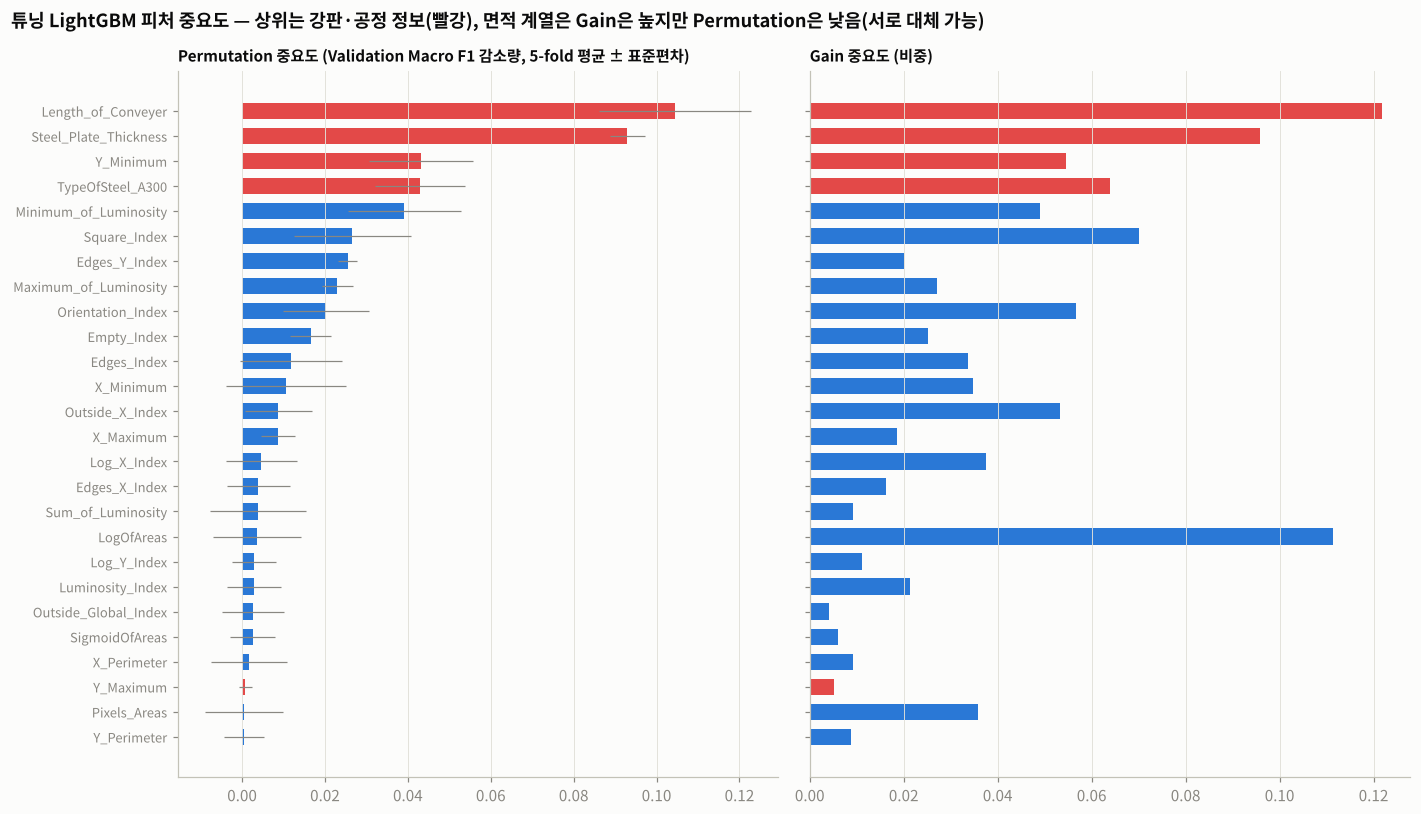

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 7.5), sharey=True)
order = imp.index[::-1]
proc = {"Length_of_Conveyer", "Steel_Plate_Thickness", "TypeOfSteel_A300", "Y_Minimum", "Y_Maximum"}
cols = [RED if f in proc else BLUE for f in order]
axes[0].barh(order, imp.loc[order, "perm_drop_mean"], xerr=imp.loc[order, "perm_drop_std"], color=cols, height=0.65,
             error_kw=dict(ecolor=MUTED, lw=0.8, capsize=0))
axes[0].set_title("Permutation 중요도 (Validation Macro F1 감소량, 5-fold 평균 ± 표준편차)", fontsize=10)
axes[1].barh(order, imp.loc[order, "gain_share"], color=cols, height=0.65)
axes[1].set_title("Gain 중요도 (비중)", fontsize=10)
for ax in axes: ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=8.5)
fig.suptitle("튜닝 LightGBM 피처 중요도 — 상위는 강판·공정 정보(빨강), 면적 계열은 Gain은 높지만 Permutation은 낮음(서로 대체 가능)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "Taegyeom_fe_feature_importance.png")

**해석 — 무엇이 중요한가**
- **Permutation 1·2위는 `Length_of_Conveyer`(Macro F1 −0.104), `Steel_Plate_Thickness`(−0.093)** 이고, 3·4위도 `Y_Minimum`·강종(`TypeOfSteel_A300`)입니다(빨강).
  결함의 모양보다 **"어떤 강판·생산 조건에서 나온 결함인가"** 가 예측에 가장 크게 쓰입니다. EDA의 강판 대리 그룹 분석(같은 조건에서 같은 유형 반복, 순도 76.6%)과 일치하며,
  처음 보는 생산 조건에서는 성능이 떨어질 수 있다는 한계를 다시 확인합니다.
- 결함 자체의 특성 중에서는 **밝기(`Minimum/Maximum_of_Luminosity`)와 형상 지표(`Square_Index`, `Edges_Y_Index`, `Orientation_Index`, `Empty_Index`)** 가 상위입니다.
- **면적 계열은 두 지표가 크게 엇갈립니다.** `LogOfAreas`는 Gain 2위지만 Permutation 18위, `Pixels_Areas`는 Gain 11위·Permutation 25위입니다.
  면적·둘레·밝기합·log 면적이 서로 거의 같은 정보(|r| ≥ 0.9)라서, 하나를 섞어도 다른 변수가 대신하기 때문입니다. **중요하지 않은 것이 아니라 "대체 가능한" 정보**로 해석해야 합니다.

## 3. 기존 지표는 이미 파생변수다 — 직관적인 파생변수의 중복 확인
데이터에는 `Empty_Index`, `Luminosity_Index`, `Edges_Index` 같은 "지표" 변수가 있습니다. 흔히 떠올리는 파생변수를 직접 계산해 기존 지표와 비교했습니다.

In [5]:
X = X_train; w = X["X_Maximum"] - X["X_Minimum"]; h = X["Y_Maximum"] - X["Y_Minimum"]
cand = {
    "채움률 = 면적 / (폭×높이)": (X["Pixels_Areas"] / (w * h).clip(lower=1), "Empty_Index"),
    "평균 밝기 = 밝기합 / 면적": (X["Sum_of_Luminosity"] / X["Pixels_Areas"], "Luminosity_Index"),
    "가장자리까지 거리 / 컨베이어 길이": (np.minimum(X["X_Minimum"], X["Length_of_Conveyer"] - X["X_Maximum"]) / X["Length_of_Conveyer"], "Edges_Index"),
    "폭 / 컨베이어 길이": (w / X["Length_of_Conveyer"], "Outside_X_Index"),
    "log(폭 / 높이)": (np.log((w + 1) / (h + 1)), "Orientation_Index"),
    "log10(면적)": (np.log10(X["Pixels_Areas"]), "LogOfAreas"),
    "log10(폭)": (np.log10(w.clip(lower=1)), "Log_X_Index"),
}
dup = pd.DataFrame([{"직접 만든 파생변수": k, "가장 비슷한 기존 변수": v, "Pearson r": round(np.corrcoef(s, X[v])[0, 1], 4)} for k, (s, v) in cand.items()])
dup.to_csv(RESULT_DIR / "Taegyeom_fe_existing_index_check.csv", index=False)
dup

,직접 만든 파생변수,가장 비슷한 기존 변수,Pearson r
0,채움률 = 면적 / (폭×높이),Empty_Index,-1.0000
1,평균 밝기 = 밝기합 / 면적,Luminosity_Index,1.0000
2,가장자리까지 거리 / 컨베이어 길이,Edges_Index,1.0000
3,폭 / 컨베이어 길이,Outside_X_Index,1.0000
4,log(폭 / 높이),Orientation_Index,-0.9568
5,log10(면적),LogOfAreas,1.0000
6,log10(폭),Log_X_Index,1.0000


- 채움률·평균 밝기·가장자리 거리·폭 비율은 기존 지표와 **|r| ≥ 0.999로 사실상 같은 값**이고, 가로세로 비도 `Orientation_Index`와 |r| ≈ 0.96입니다.
- 즉 원 데이터 제작 단계에서 **대표적인 형상·밝기·위치 파생변수가 이미 지표로 포함**되어 있습니다. 이런 변수를 다시 만들면 정보가 추가되지 않으므로 제외하고,
  **기존 지표로 표현되지 않는 조합**만 새로 설계했습니다(아래 4번).

## 4. 새 파생변수 설계
| 그룹 | 변수 | 계산식 | 설계 근거 |
|---|---|---|---|
| 형상 | `compactness` | (X_Perimeter + Y_Perimeter) / √Pixels_Areas | 같은 면적이라도 윤곽이 복잡한(긁힘·얼룩 경계) 결함을 구분. 둘레·면적 계열은 Gain 중요도가 높음 |
| 형상 | `perimeter_ratio_log` | log(X_Perimeter / Y_Perimeter) | 가로/세로 윤곽 길이 비 — 방향성 지표(`Orientation_Index`)는 bounding box 기준이라 윤곽 기준 비율은 별도 정보 |
| 형상 | `x_straightness` | X_Perimeter / (폭 + 1) | 폭 대비 X 방향 윤곽이 얼마나 구불구불한가 (직선형 긁힘 vs 불규칙 얼룩) |
| 밝기 | `lum_range` | Max − Min luminosity | Permutation 상위인 `Minimum/Maximum_of_Luminosity`의 결합. 결함 내부 밝기 대비 |
| 밝기 | `lum_contrast` | (Max − Min) / (Max + Min) | 조명 수준에 덜 민감한 상대 대비 |
| 밝기 | `lum_mean_position` | (평균 밝기 − Min) / (Max − Min + 1) | 평균 밝기가 밝기 범위 중 어디에 있는가 (어두운 점이 일부인지 전체인지) |
| 위치 | `x_center_rel` | X 중심 / Length_of_Conveyer | 기존 `Edges_Index`(가장 가까운 가장자리까지 거리)와 달리 **좌/우를 구분**하는 폭 방향 상대 위치 |
| 위치 | `x_center_dist` | \|x_center_rel − 0.5\| | 중앙에서 떨어진 정도 |
| 강판 맥락 | `plate_defect_count` | 같은 (컨베이어 길이, 두께, 강종) 조합의 결함 수 — **Training fold에서만 계산** | 중요도 1·2위인 컨베이어 길이·두께와 강종을 하나의 "강판 조건"으로 결합. EDA에서 같은 조건 내 동일 유형 반복(순도 76.6%) 확인 |
| 강판 맥락 | `thickness_per_conveyer` | Steel_Plate_Thickness / Length_of_Conveyer | 중요도 1·2위 변수의 비율 |

In [6]:
X_fe_all = add_features(X_train)
new_cols = [c for c in X_fe_all.columns if c not in FEATURES]
plate_tmp = PlateContextEncoder().fit(X_train).transform(X_train)[["plate_defect_count", "thickness_per_conveyer"]]   # 설명용(전체 Train)
newX = pd.concat([X_fe_all[new_cols], plate_tmp], axis=1)
mi_new = pd.Series(mutual_info_classif(newX, y_train, random_state=RS), index=newX.columns)
maxcorr = {c: X_train.corrwith(newX[c]).abs().sort_values(ascending=False).head(1) for c in newX.columns}
desc_new = pd.DataFrame({"MI (Train)": mi_new.round(3),
                         "가장 상관 높은 기존 변수": [maxcorr[c].index[0] for c in newX.columns],
                         "|r|": [round(maxcorr[c].iloc[0], 3) for c in newX.columns]})
desc_new.to_csv(RESULT_DIR / "Taegyeom_fe_new_feature_check.csv")
print("참고: 기존 변수 MI 상위 = Steel_Plate_Thickness 0.56, Length_of_Conveyer 0.55, Outside_X_Index 0.53")
desc_new

참고: 기존 변수 MI 상위 = Steel_Plate_Thickness 0.56, Length_of_Conveyer 0.55, Outside_X_Index 0.53


,MI (Train),가장 상관 높은 기존 변수,|r|
compactness,0.204,Y_Perimeter,0.824
perimeter_ratio_log,0.335,Orientation_Index,0.841
x_straightness,0.257,Edges_X_Index,0.803
lum_range,0.315,Minimum_of_Luminosity,0.817
lum_contrast,0.360,Minimum_of_Luminosity,0.899
lum_mean_position,0.351,Minimum_of_Luminosity,0.144
x_center_rel,0.468,X_Minimum,0.985
x_center_dist,0.370,Edges_Index,0.980
plate_defect_count,0.690,Log_X_Index,0.450
thickness_per_conveyer,0.947,Steel_Plate_Thickness,0.985


- 새 변수들은 기존 변수와 |r| 0.8~0.9 수준으로 관련되지만 완전히 같지는 않습니다. 단, **`x_center_rel`(|r| 0.985)·`x_center_dist`(0.980)·`thickness_per_conveyer`(0.985)는 기존 변수와 거의 같아** 새 정보가 적을 것으로 예상됩니다.
- `thickness_per_conveyer`(MI 0.95)와 `plate_defect_count`(MI 0.69)는 기존 최고 MI(0.56)보다 높습니다. 두께·컨베이어 길이 조합이 **강판을 거의 식별**하기 때문으로,
  클래스 구분력이 높다기보다 "같은 강판의 다른 결함"을 알아보는 신호에 가깝습니다(일반화 한계와 같은 맥락).

## 5. 파생변수 적용 전후 비교 (5-fold CV, 같은 fold·같은 하이퍼파라미터)

In [7]:
FEATURE_SETS = {   # 이름: (행 단위 그룹, 강판 맥락 포함, 제외할 변수)
    "원본 (26개)":        ((), False, []),
    "+형상":              (("형상",), False, []),
    "+밝기":              (("밝기",), False, []),
    "+위치":              (("위치",), False, []),
    "+강판 맥락":         ((), True, []),
    "+전체 (36개)":       (("형상", "밝기", "위치"), True, []),
    "고상관 변수 제거":   ((), False, ["Y_Maximum", "X_Maximum", "Sum_of_Luminosity", "Pixels_Areas"]),
}
data, specs = {}, {}
for sname, (groups, plate, drop) in FEATURE_SETS.items():
    Xs = add_features(X_train, groups).drop(columns=drop); feats = list(Xs.columns); data[sname] = Xs
    specs[("튜닝 LightGBM + SMOTENC", sname)] = dict(build=lambda f=feats, p=plate: tuned_lgbm(f, p))
    specs[("LightGBM (기본)", sname)] = dict(build=lambda f=feats, p=plate: ImbPipeline(
        ([("plate", PlateContextEncoder())] if p else []) +
        [("prep", build_preprocessor(f + (["plate_defect_count", "thickness_per_conveyer"] if p else []))),
         ("model", LGBMClassifier(random_state=RS, n_jobs=1, verbose=-1))]))
    specs[("Logistic Regression", sname)] = dict(build=lambda f=feats, p=plate: ImbPipeline(
        ([("plate", PlateContextEncoder())] if p else []) +
        [("prep", build_preprocessor(f + (["plate_defect_count", "thickness_per_conveyer"] if p else []), scale=True)),
         ("model", LogisticRegression(max_iter=5000, random_state=RS))]))

def run_all():
    out = {}
    for sname, Xs in data.items():     # 피처 세트마다 입력 데이터가 다르므로 세트 단위로 병렬 실행
        out.update(run_many({k: v for k, v in specs.items() if k[1] == sname}, Xs, y_train, n_jobs=-1))
    return out

t0 = time.perf_counter()
fe_runs = cached("fe_runs", run_all)
print(f"소요 {time.perf_counter() - t0:.0f}초")
fs = summarize_runs(list(fe_runs.values())); fs.index = pd.MultiIndex.from_tuples(list(fe_runs), names=["model", "feature_set"])
fs["delta_vs_original"] = [fs.loc[(m, s), "macro_f1_mean"] - fs.loc[(m, "원본 (26개)"), "macro_f1_mean"] for m, s in fs.index]
fs.to_csv(RESULT_DIR / "Taegyeom_fe_cv_summary.csv")
MODELS = ["Logistic Regression", "LightGBM (기본)", "튜닝 LightGBM + SMOTENC"]; SETS = list(FEATURE_SETS)
tbl = fs["macro_f1_mean"].unstack("feature_set").reindex(index=MODELS, columns=SETS)
print("Macro F1 (5-fold 평균)"); display(tbl.round(4))
print("원본 대비 변화량"); display(fs["delta_vs_original"].unstack("feature_set").reindex(index=MODELS, columns=SETS).round(4))

소요 0초
Macro F1 (5-fold 평균)


feature_set,원본 (26개),+형상,+밝기,+위치,+강판 맥락,+전체 (36개),고상관 변수 제거
model,,,,,,,
Logistic Regression,0.7191,0.7181,0.7234,0.7195,0.7201,0.7249,0.7201
LightGBM (기본),0.8044,0.8072,0.8069,0.8080,0.8130,0.8181,0.7988
튜닝 LightGBM + SMOTENC,0.8309,0.8292,0.8232,0.8302,0.8272,0.8262,0.8197


원본 대비 변화량


feature_set,원본 (26개),+형상,+밝기,+위치,+강판 맥락,+전체 (36개),고상관 변수 제거
model,,,,,,,
Logistic Regression,0.0,-0.0011,0.0043,0.0004,0.0009,0.0058,0.0010
LightGBM (기본),0.0,0.0028,0.0025,0.0036,0.0087,0.0137,-0.0056
튜닝 LightGBM + SMOTENC,0.0,-0.0016,-0.0077,-0.0007,-0.0037,-0.0047,-0.0112


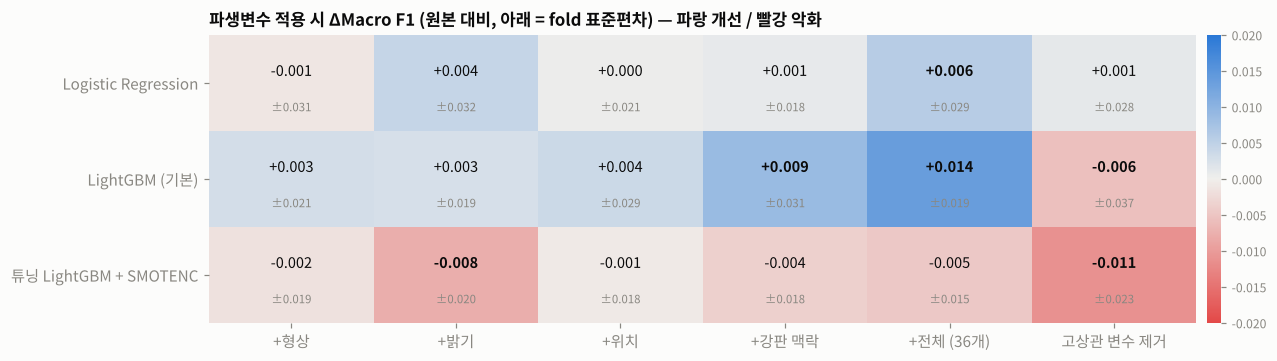

In [8]:
delta = fs["delta_vs_original"].unstack("feature_set").reindex(index=MODELS, columns=SETS[1:])
std = fs["macro_f1_std"].unstack("feature_set").reindex(index=MODELS, columns=SETS[1:])
fig, ax = plt.subplots(figsize=(12, 3.4))
im = ax.imshow(delta.values, cmap=DIV, norm=TwoSlopeNorm(vmin=-0.02, vcenter=0, vmax=0.02), aspect="auto")
for i in range(delta.shape[0]):
    for j in range(delta.shape[1]):
        v = delta.values[i, j]
        ax.text(j, i - 0.13, f"{v:+.3f}", ha="center", va="center", fontsize=9.5, color=INK, fontweight="bold" if abs(v) >= 0.005 else None)
        ax.text(j, i + 0.25, f"±{std.values[i, j]:.3f}", ha="center", va="center", fontsize=7.5, color=MUTED)
ax.set_xticks(range(delta.shape[1]), delta.columns); ax.set_yticks(range(len(MODELS)), MODELS); ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01); cb.outline.set_visible(False); cb.ax.tick_params(labelsize=8)
ax.set_title("파생변수 적용 시 ΔMacro F1 (원본 대비, 아래 = fold 표준편차) — 파랑 개선 / 빨강 악화")
save(fig, "Taegyeom_fe_delta_macro_f1.png")

In [9]:
# 같은 fold에서 짝지어 비교: 튜닝 LightGBM 기준, fold별로 원본보다 좋아진 횟수
base_f = fe_runs[("튜닝 LightGBM + SMOTENC", "원본 (26개)")]["folds"]["val_macro_f1"].values
paired = pd.DataFrame({s: {"ΔMacro F1 평균": round((fe_runs[("튜닝 LightGBM + SMOTENC", s)]["folds"]["val_macro_f1"].values - base_f).mean(), 4),
                           "개선된 fold 수": f"{((fe_runs[('튜닝 LightGBM + SMOTENC', s)]['folds']['val_macro_f1'].values - base_f) > 0).sum()}/5",
                           "Pastry F1": round(per_class_report(y_train, fe_runs[('튜닝 LightGBM + SMOTENC', s)]['oof']).loc['Pastry', 'f1'], 3),
                           "Bumps F1": round(per_class_report(y_train, fe_runs[('튜닝 LightGBM + SMOTENC', s)]['oof']).loc['Bumps', 'f1'], 3),
                           "Other_Faults F1": round(per_class_report(y_train, fe_runs[('튜닝 LightGBM + SMOTENC', s)]['oof']).loc['Other_Faults', 'f1'], 3),
                           "Bumps↔Other 혼동": int(key_error_counts(y_train, fe_runs[('튜닝 LightGBM + SMOTENC', s)]['oof']).iloc[2])}
                       for s in SETS}).T
paired.to_csv(RESULT_DIR / "Taegyeom_fe_tuned_lgbm_paired.csv")
paired

,ΔMacro F1 평균,개선된 fold 수,Pastry F1,Bumps F1,Other_Faults F1,Bumps↔Other 혼동
원본 (26개),0.0,0/5,0.675,0.701,0.759,162
+형상,-0.0016,4/5,0.675,0.697,0.75,169
+밝기,-0.0077,2/5,0.661,0.682,0.738,177
+위치,-0.0007,3/5,0.675,0.697,0.756,167
+강판 맥락,-0.0037,1/5,0.669,0.692,0.755,166
+전체 (36개),-0.0047,2/5,0.682,0.685,0.745,172
고상관 변수 제거,-0.0112,1/5,0.646,0.681,0.736,176


**해석 — 파생변수 효과는 모델에 따라 반대 방향**
- **기본 LightGBM은 파생변수로 개선**됩니다: +전체 **+0.014**(0.804 → 0.818), +강판 맥락 +0.009. 하이퍼파라미터를 조정하지 않은 모델에는 비율·결합 변수가 분할을 쉽게 만들어 도움이 됩니다.
- **Logistic Regression**도 +전체 +0.006, +밝기 +0.004로 소폭 개선되지만 0.72 수준에 머뭅니다.
- **튜닝 LightGBM + SMOTENC(최종 후보)는 모든 파생변수 세트에서 소폭 하락**(−0.001 ~ −0.008)했습니다.
  - 형상·위치 추가는 차이가 ±0.002 이내로 사실상 변화가 없고(형상은 5개 fold 중 4개에서 근소하게 개선), 밝기·강판 맥락·전체 추가는 −0.004 ~ −0.008입니다.
  - 원인: (1) 대표적인 파생변수가 이미 지표 변수로 들어 있어(3번) 새로 추가되는 정보가 적고, (2) 하이퍼파라미터가 **원본 26개 피처 기준으로 튜닝**되어 있어 피처가 늘면 `colsample_bytree` 등 설정과 맞지 않을 수 있으며,
    (3) SMOTENC가 늘어난 피처 공간에서 합성 표본을 만들면서 상관된 피처끼리의 노이즈도 함께 커질 수 있습니다.
- **고상관 변수 제거**(Y_Maximum·X_Maximum·Sum_of_Luminosity·Pixels_Areas)는 튜닝 모델에서 −0.011로 가장 크게 악화되었습니다. 상관이 높아도 트리 모델에는 분할 후보로서 여전히 쓸모가 있다는 뜻입니다.
- 클래스별로 보면 파생변수 추가 시 **Bumps ↔ Other_Faults 혼동이 162건 → 166~177건으로 오히려 늘어** 이 데이터의 핵심 오류원을 줄이지 못했습니다.

**중간 결론**: 하이퍼파라미터를 고정하면 파생변수는 튜닝 전 모델에서만 효과가 있었습니다(최대 +0.014). 고정된 설정이 파생변수에 불리했을 수 있으므로 6번에서 파생변수에 맞춰 다시 튜닝해 비교합니다.
참고로 이 노트북의 원본 튜닝 LightGBM 점수(0.8309)가 튜닝 노트북(0.8298)과 조금 다른 것은 최종 설정 파일에 하이퍼파라미터를 소수점 4자리로 반올림해 저장했기 때문입니다.

## 6. 파생변수에 맞춘 재튜닝 — 공정한 비교
5번 비교는 원본 26개 피처로 튜닝한 하이퍼파라미터를 그대로 썼기 때문에 파생변수 세트에 불리할 수 있습니다.
여기서는 **파생변수 세트마다 하이퍼파라미터를 다시 튜닝**한 뒤, "원본 + 원본 튜닝"과 "파생변수 + 파생변수 튜닝"을 비교합니다.

| 항목 | 설정 |
|---|---|
| 대상 세트 | `+전체 (36개)` (기본 LightGBM에서 개선폭 최대, +0.014), `+강판 맥락` (중요도 1·2위 변수 결합, +0.009) |
| 탐색 | 튜닝 노트북과 **동일한 탐색 공간·탐색 횟수(30)·random_state** 의 `RandomizedSearchCV` (샘플러 사용 여부·class_weight 포함) |
| 비교 | 팀 공통 5-fold + **반복 층화 CV(5×3)** — 원본 튜닝 모델의 반복 CV 결과는 튜닝 노트북 결과(같은 분할)를 사용 |

In [10]:
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import RandomizedSearchCV, RepeatedStratifiedKFold

def lgbm_search_pipe(feats, plate):
    feats2 = list(feats) + (["plate_defect_count", "thickness_per_conveyer"] if plate else [])
    sm = lambda: SMOTENC(categorical_features=discrete_indices(feats2), sampling_strategy=over_strategy(1), k_neighbors=5, random_state=RS)
    steps = ([("plate", PlateContextEncoder())] if plate else []) + [
        ("prep", build_preprocessor(feats2)), ("sampler", sm()),
        ("model", LGBMClassifier(random_state=RS, n_jobs=1, verbose=-1, subsample_freq=1))]
    space = {"sampler": [sm(), "passthrough"], "model__class_weight": [None, "balanced"],
             "model__n_estimators": randint(150, 900), "model__learning_rate": loguniform(0.01, 0.15),
             "model__num_leaves": randint(8, 64), "model__max_depth": [-1, 4, 6, 8, 10],
             "model__min_child_samples": randint(5, 40), "model__subsample": uniform(0.6, 0.4),
             "model__colsample_bytree": uniform(0.4, 0.6), "model__reg_lambda": loguniform(1e-3, 10)}
    return ImbPipeline(steps), space

RETUNE_SETS = {"+전체 (36개)": (("형상", "밝기", "위치"), True), "+강판 맥락": ((), True)}
retune = {}
t0 = time.perf_counter()
for sname, (groups, plate) in RETUNE_SETS.items():
    Xs = add_features(X_train, groups); pipe, space = lgbm_search_pipe(list(Xs.columns), plate)
    def _search(pipe=pipe, space=space, Xs=Xs):
        rs = RandomizedSearchCV(pipe, space, n_iter=30, scoring="f1_macro", cv=CV, n_jobs=-1, random_state=RS,
                                return_train_score=True, refit=False)
        rs.fit(Xs, y_train); return pd.DataFrame(rs.cv_results_)
    res = cached(("retune_search", sname), _search)
    best = res.loc[res["rank_test_score"].idxmin()]
    retune[sname] = dict(X=Xs, pipe=pipe, params=best["params"], cv=best["mean_test_score"], std=best["std_test_score"])
    print(f"{sname:12s} 재튜닝 최고 5-fold Macro F1 {best['mean_test_score']:.4f} ± {best['std_test_score']:.4f}  "
          f"(샘플러: {'SMOTENC' if not isinstance(best['params']['sampler'], str) else '없음'})")
print(f"소요 {time.perf_counter() - t0:.0f}초")

+전체 (36개)    재튜닝 최고 5-fold Macro F1 0.8317 ± 0.0058  (샘플러: SMOTENC)
+강판 맥락       재튜닝 최고 5-fold Macro F1 0.8326 ± 0.0117  (샘플러: SMOTENC)
소요 0초


In [11]:
# 반복 층화 CV(5×3): 튜닝 노트북과 같은 분할(RepeatedStratifiedKFold random_state=42)
RCV = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RS)
def rep_eval(sname):
    r = retune[sname]; p = clone(r["pipe"]).set_params(**r["params"])
    return run_many({sname: dict(build=lambda p=p: clone(p))}, r["X"], y_train, cv=RCV, n_jobs=-1)[sname]["folds"]["val_macro_f1"].values

t0 = time.perf_counter()
rep_scores = {s: cached(("retune_repeated", s), lambda s=s: rep_eval(s)) for s in RETUNE_SETS}
print(f"소요 {time.perf_counter() - t0:.0f}초")

tune_cache = pickle.load(open(PROJECT_ROOT / "results/tuning/Taegyeom_tuning_cache.pkl", "rb"))
orig_rep = tune_cache["repeated"]["LightGBM"]["folds"]["val_macro_f1"].values
orig_search = tune_cache[("search", "LightGBM")]; orig_best = orig_search.loc[orig_search["rank_test_score"].idxmin()]

def clean_params(p):
    return {k.split("__")[-1]: ("SMOTENC" if (k == "sampler" and not isinstance(v, str)) else (round(v, 4) if isinstance(v, float) else v)) for k, v in p.items()}

rows = [{"설정": "원본 26개 + 원본 튜닝 (현재 최종 후보)", "5-fold Macro F1": round(orig_best["mean_test_score"], 4),
         "반복 CV(5×3)": f"{orig_rep.mean():.4f} ± {orig_rep.std():.4f}", "Δ 반복 CV": 0.0, "원본보다 좋은 fold": "—"}]
for s in RETUNE_SETS:
    d = rep_scores[s] - orig_rep
    rows.append({"설정": f"{s} + 재튜닝", "5-fold Macro F1": round(retune[s]["cv"], 4),
                 "반복 CV(5×3)": f"{rep_scores[s].mean():.4f} ± {rep_scores[s].std():.4f}",
                 "Δ 반복 CV": round(d.mean(), 4), "원본보다 좋은 fold": f"{(d > 0).sum()}/15"})
retune_tbl = pd.DataFrame(rows).set_index("설정")
retune_tbl.to_csv(RESULT_DIR / "Taegyeom_fe_retune_comparison.csv")
pd.DataFrame({s: clean_params(retune[s]["params"]) for s in RETUNE_SETS} | {"원본 26개": clean_params(orig_best["params"])}).to_csv(
    RESULT_DIR / "Taegyeom_fe_retune_best_params.csv")
display(retune_tbl)
pd.DataFrame({s: clean_params(retune[s]["params"]) for s in RETUNE_SETS} | {"원본 26개": clean_params(orig_best["params"])})

소요 0초


,5-fold Macro F1,반복 CV(5×3),Δ 반복 CV,원본보다 좋은 fold
설정,,,,
원본 26개 + 원본 튜닝 (현재 최종 후보),0.8298,0.8260 ± 0.0179,0.0000,—
+전체 (36개) + 재튜닝,0.8317,0.8295 ± 0.0180,0.0035,10/15
+강판 맥락 + 재튜닝,0.8326,0.8278 ± 0.0191,0.0018,8/15


,+전체 (36개),+강판 맥락,원본 26개
class_weight,balanced,balanced,None
colsample_bytree,0.4221,0.6026,0.8779
learning_rate,0.0521,0.1285,0.0164
max_depth,4,-1,10
min_child_samples,32,16,25
n_estimators,715,659,764
num_leaves,30,46,26
reg_lambda,0.013,0.0975,0.0025
subsample,0.9633,0.7204,0.7837
sampler,SMOTENC,SMOTENC,SMOTENC


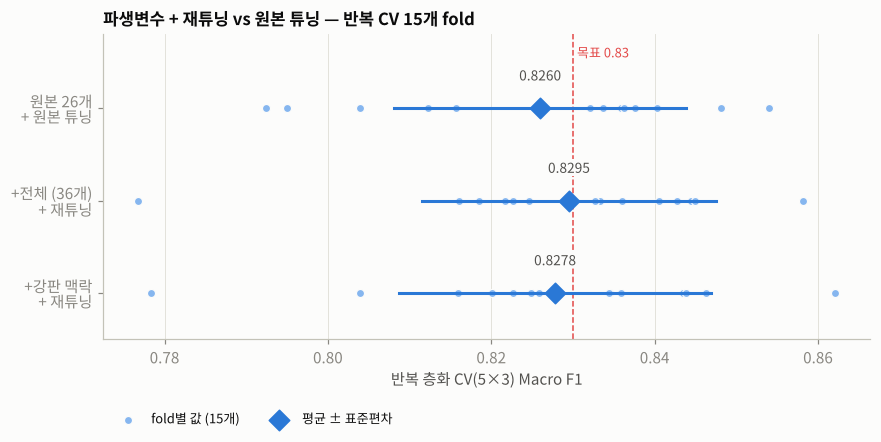

In [12]:
fig, ax = plt.subplots(figsize=(9, 3.6))
labels = ["원본 26개\n+ 원본 튜닝"] + [f"{s}\n+ 재튜닝" for s in RETUNE_SETS]
series = [orig_rep] + [rep_scores[s] for s in RETUNE_SETS]
for i, v in enumerate(series):
    ax.scatter(v, [i] * len(v), s=28, color=BLUE_LIGHT, edgecolor=SURFACE, lw=0.8, zorder=2, label="fold별 값 (15개)" if i == 0 else None)
    ax.plot([v.mean() - v.std(), v.mean() + v.std()], [i, i], color=BLUE, lw=2, zorder=3)
    ax.scatter([v.mean()], [i], s=90, marker="D", color=BLUE, zorder=4, label="평균 ± 표준편차" if i == 0 else None)
    ax.text(v.mean(), i - 0.3, f"{v.mean():.4f}", ha="center", fontsize=9, color=INK2, bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1))
ax.axvline(0.83, color=RED, lw=1, ls="--"); ax.text(0.8305, -0.55, "목표 0.83", color=RED, fontsize=8.5)
ax.set_yticks(range(len(labels)), labels); ax.invert_yaxis(); ax.set_ylim(len(labels) - 0.5, -0.8); ax.grid(axis="y", visible=False)
ax.set_xlabel("반복 층화 CV(5×3) Macro F1"); ax.legend(loc="upper left", bbox_to_anchor=(0, -0.2), ncol=2, frameon=False, fontsize=8.5)
ax.set_title("파생변수 + 재튜닝 vs 원본 튜닝 — 반복 CV 15개 fold")
save(fig, "Taegyeom_fe_retune_repeated_cv.png")

**해석 — 재튜닝하면 차이가 사라지거나 소폭 개선**
- 하이퍼파라미터를 고정했을 때(5번)는 파생변수가 −0.005 ~ −0.008이었지만, **파생변수에 맞춰 다시 튜닝하면 원본과 같거나 약간 높아집니다.**
  - `+전체 (36개)`: 5-fold 0.832 ± 0.006, 반복 CV **0.8295** (원본 0.8260 대비 **+0.0035**, 15개 fold 중 10개에서 개선)
  - `+강판 맥락`: 5-fold 0.833 ± 0.012, 반복 CV 0.8278 (+0.0018, 8/15)
  - 즉 5번의 하락은 **파생변수 자체보다 "원본 기준 하이퍼파라미터와 맞지 않아서"** 생긴 부분이 컸습니다(재튜닝 결과 `colsample_bytree` 0.88 → 0.42, `max_depth` 10 → 4 등 설정이 크게 바뀜).
- **하지만 개선 폭은 우연과 구분하기 어렵습니다.** `+전체`의 fold별 차이는 평균 +0.0035, 표준편차 0.013으로 차이/표준오차 ≈ 1.0 수준이며(반복 CV fold끼리는 서로 독립이 아니라 실제 불확실성은 더 큼),
  0.83 이상인 fold 수도 원본과 같은 8/15입니다. 목표 0.83을 안정적으로 넘게 만들지는 못했습니다.
- `+전체`에는 `plate_defect_count`(학습 데이터의 같은 강판 조건 결함 수)가 포함됩니다. 처음 보는 강판 조건에서는 0이 되므로 **강판 조건에 대한 의존(일반화 한계)을 더 키울 수 있습니다.**

**최종 판단: `+전체 (36개) + 재튜닝` LightGBM을 최종 모델로 선택**
- 반복 CV(5×3) 평균이 가장 높은 설정(0.8295, 원본 대비 +0.0035, 15개 fold 중 10개에서 개선)이며, 5-fold에서도 fold 간 편차가 가장 작았습니다(± 0.006).
- 개선 폭이 fold 간 편차 안이라 통계적으로 확실한 우위는 아니며, `plate_defect_count`로 인해 **강판 조건 의존이 커질 수 있다는 한계**를 함께 기록합니다.
- 원본 26개 피처 튜닝 모델은 **이전 후보**로 남기고, 두 모델의 Test 결과는 `Taegyeom_final_evaluation.ipynb`에서 함께 보고합니다.
- 튜터님 질문에 대한 답: *"피처 중요도를 보고 중요 피처 기반 파생변수를 만들었고, 고정 설정에서는 효과가 없었지만 파생변수에 맞춰 재튜닝하자 반복 CV +0.0035로 소폭 개선되어 최종 모델에 반영했다.
  대표적인 파생변수(채움률·평균 밝기·가장자리 거리 등)는 원 데이터에 이미 지표로 들어 있어 개선 폭은 크지 않았다."*

> **이후 경과**: 이 36개 피처를 고정한 상태에서 모델을 처음부터 다시 튜닝하고 앙상블한 결과(`Taegyeom_modeling_v2.ipynb`), Soft Voting(ExtraTrees + Random Forest + GBM)이 반복 CV 0.8395로 이 LightGBM(0.8295)보다 높아 **최종 모델은 Soft Voting으로 교체**되었습니다. 파생변수 36개는 그대로 사용합니다.